In [ ]:
from pathlib import Path

import numpy as np
import lightning as L
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import torch
import torchmetrics

import gc
from minerva.data.data_modules.base import MinervaDataModule
from minerva.data.datasets.base import SimpleDataset
from minerva.models.nets.image.deeplabv3 import DeepLabV3
from minerva.transforms.transform import Repeat, CastTo, Unsqueeze, TransformPipeline

from utils.transforms import BinarizeLabel
from utils.plot import plot_segmentation_data
from utils.loss import BCEDiceLoss
from utils.data import NumpyFolderReader
from utils.metrics import search_best_threshold, compute_binary_segmentation_metrics, collect_logits_and_targets, plot_threshold_search, plot_auprc_curve, WithTargets, stack_preallocated

## Create the Data Module

In [2]:
root_data_dir = Path("../../../../data/processed/channel_identification/cigChannel/partition_method_random/")
seed = 42

In [ ]:
###########################
# Train dataset
###########################
train_data_reader = NumpyFolderReader(
    root_data_dir / "train" / "data",
    sort_method=["text", "numeric"],
    delimiter="_",
    key_index=[0, 1],
)
train_label_reader = NumpyFolderReader(
    root_data_dir / "train" / "label",
    sort_method=["text", "numeric"],
    delimiter="_",
    key_index=[0, 1],
)
train_data_transforms = TransformPipeline(
    [
        Unsqueeze(0),
        Repeat(axis=0, n_repetitions=3),
        CastTo("float32"),
    ]
)

train_label_transforms = TransformPipeline(
    [
        BinarizeLabel(),
        Unsqueeze(0),
        CastTo("int64"),
    ]
)

train_dataset = SimpleDataset(
    readers=[train_data_reader, train_label_reader],
    transforms=[train_data_transforms, train_label_transforms],
)

###########################
# Validation dataset
###########################
val_data_reader = NumpyFolderReader(
    root_data_dir / "val" / "data",
    sort_method=["text", "numeric"],
    delimiter="_",
    key_index=[0, 1],
)
val_label_reader = NumpyFolderReader(
    root_data_dir / "val" / "label",
    sort_method=["text", "numeric"],
    delimiter="_",
    key_index=[0, 1],
)
val_data_transforms = TransformPipeline(
    [
        Unsqueeze(0),
        Repeat(axis=0, n_repetitions=3),
        CastTo("float32"),
    ]
)
val_label_transforms = TransformPipeline(
    [
        BinarizeLabel(),
        Unsqueeze(0),
        CastTo("int64"),
    ]
)

val_dataset = SimpleDataset(
    readers=[val_data_reader, val_label_reader],
    transforms=[val_data_transforms, val_label_transforms],
)

###########################
# Test dataset
###########################
test_data_reader = NumpyFolderReader(
    root_data_dir / "test" / "data",
    sort_method=["text", "numeric"],
    delimiter="_",
    key_index=[0, 1],
)
test_label_reader = NumpyFolderReader(
    root_data_dir / "test" / "label",
    sort_method=["text", "numeric"],
    delimiter="_",
    key_index=[0, 1],
)
test_data_transforms = TransformPipeline(
    [Unsqueeze(0), Repeat(axis=0, n_repetitions=3), CastTo("float32")]
)  # Transforms to first reader (data)
test_label_transforms = TransformPipeline([BinarizeLabel(), Unsqueeze(0), CastTo("int64")])

test_dataset = SimpleDataset(
    readers=[test_data_reader, test_label_reader],
    transforms=[test_data_transforms, test_label_transforms],
)

In [4]:
train_x, train_y = train_dataset[0]
print(f"Train sample shapes: {train_x.shape} (dtype: {train_x.dtype}), Label Shape: {train_y.shape} (dtype: {train_y.dtype})")

val_x, val_y = val_dataset[0]
print(f"Validation sample shapes: {val_x.shape} (dtype: {val_x.dtype}), Label Shape: {val_y.shape} (dtype: {val_y.dtype})")

test_x, test_y = test_dataset[0]
print(f"Test sample shapes: {test_x.shape} (dtype: {test_x.dtype}), Label Shape: {test_y.shape} (dtype: {test_y.dtype})")

Train sample shapes: (3, 256, 256) (dtype: float32), Label Shape: (1, 256, 256) (dtype: int64)
Validation sample shapes: (3, 256, 256) (dtype: float32), Label Shape: (1, 256, 256) (dtype: int64)
Test sample shapes: (3, 256, 256) (dtype: float32), Label Shape: (256, 256) (dtype: int64)


In [5]:
data_module = MinervaDataModule(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    test_dataset=test_dataset,
    batch_size=128,
    num_workers=4,
    drop_last=True,
    name="cigChannel Dataset"
 )

print(data_module)

                🆔 cigChannel Dataset
└── Predict Split: test
📂 Datasets:
   ├── Train Dataset:
   │      ==================================================
   │                 📂 SimpleDataset Information            
   │      ==================================================
   │      📌 Dataset Type: SimpleDataset
   │         └── Reader 0: NumpyFolderReader at '../../../../data/processed/channel_identification/cigChannel/partition_method_random/train/data' (71680 files)
   │         │     └── Transform: TransformPipeline(transforms=[Unsqueeze(axis=0), Repeat(axis=0, n_repetitions=3), CastTo(dtype=float32)])
   │         └── Reader 1: NumpyFolderReader at '../../../../data/processed/channel_identification/cigChannel/partition_method_random/train/label' (71680 files)
   │         │     └── Transform: TransformPipeline(transforms=[Unsqueeze(axis=0), CastTo(dtype=int64)])
   │         │
   │         └── Total Readers: 2
   │      ==================================================
   ├──

### Plot a sample from the training set

/tmp/ipykernel_1217/4255077800.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


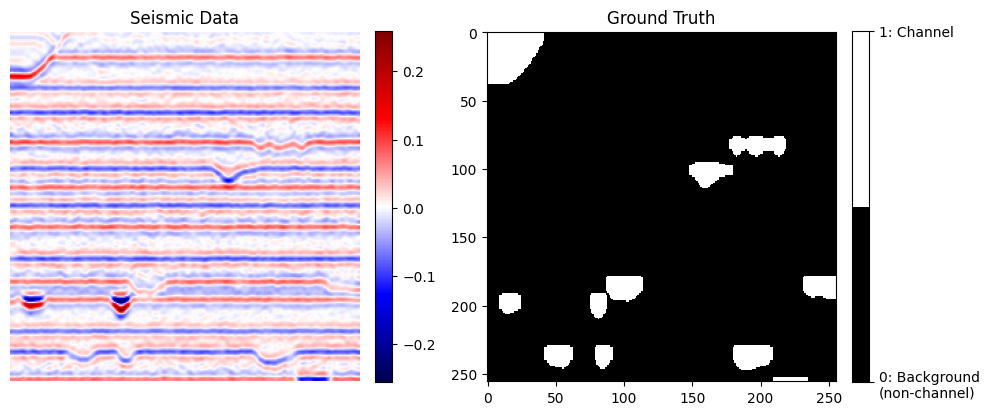

In [10]:
label_map = {
    0: "Background (non-channel)",
    1: "Channel",
}

color_map = {0: "#000000", 1: "#ffffff"}

x, y = train_dataset[10]
fig = plot_segmentation_data(
    num_classes=2,
    data=x[0, :, :],
    label=y[0, :, :],
    prediction=None,
    per_image_size=(5, 6),
    label_names=label_map,
    class_colors=color_map,
)
fig.show()

## Model

In [12]:
model = DeepLabV3(
    num_classes=1,
    loss_fn=BCEDiceLoss(
        bce_weight=1.0,
        dice_weight=0.0,
        pos_weight=None,  # optionally set this if positives are rare
    ),
)
model

DeepLabV3(
  (backbone): DeepLabV3Backbone(
    (RN50model): ResNet(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu)

## Trainer

In [13]:
trainer = L.Trainer(
    max_epochs=3,
    logger=False,
    enable_checkpointing=False,
    accelerator="gpu",
    devices=1,
    limit_train_batches=10,
    limit_val_batches=10,
    precision="16-mixed"
)

trainer

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


### Train the model

In [14]:
trainer.fit(model, data_module)

You are using a CUDA device ('NVIDIA RTX A6000') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/home/vscode/.local/lib/python3.10/site-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name     ┃ Type                    ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ backbone │ DeepLabV3Backbone       │ 25.6 M │ train │     0 │
│ 1 │ fc       │ DeepLabV3PredictionHead │ 16.1 M │ train │     0 │
│ 2 │ loss_fn  │ BCEDiceLoss             │      0 │ train │     0 │
└───┴──────────┴─────────────────────────┴────────┴───────┴───────┘

Trainable params: 41.7 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 41.7 M                                                                                               
Total estimated model params size (MB): 166                                                                        
Modules in train mode: 188                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/home/vscode/.local/lib/python3.10/site-packages/lightning/pytorch/core/module.py:522: You called 
`self.log('val_loss', ..., logger=True)` but have no logger configured. You can enable one by doing 
`Trainer(logger=ALogger(...))`

/home/vscode/.local/lib/python3.10/site-packages/lightning/pytorch/core/module.py:522: You called 
`self.log('train_loss', ..., logger=True)` but have no logger configured. You can enable one by doing 
`Trainer(logger=ALogger(...))`

`Trainer.fit` stopped: `max_epochs=3` reached.


## Calculate metrics on the test set

In [15]:
model = WithTargets(return_dict=True)(model)
model

DeepLabV3(
  (backbone): DeepLabV3Backbone(
    (RN50model): ResNet(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu)

In [16]:
val_loader = data_module.val_dataloader()
val_results = trainer.predict(model=model, dataloaders=val_loader)
val_logits = stack_preallocated(val_results, key="logits").squeeze(1)  # Remove channel dimension if it's 1
val_targets = stack_preallocated(val_results, key="y")

del val_results  # Free up memory
gc.collect()
torch.cuda.empty_cache()

print(f"Validation logits shape: {val_logits.shape}, Validation targets shape: {val_targets.shape}")

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Output()

Validation logits shape: torch.Size([10240, 256, 256]), Validation targets shape: torch.Size([10240, 1, 256, 256])


In [18]:
test_loader = data_module.test_dataloader()
test_results = trainer.predict(model=model, dataloaders=test_loader)
test_logits = stack_preallocated(test_results, key="logits").squeeze(1)  # Remove channel dimension if it's 1
test_targets = stack_preallocated(test_results, key="y")

del test_results  # Free up memory
gc.collect()
torch.cuda.empty_cache()

print(f"Test logits shape: {test_logits.shape}, Test targets shape: {test_targets.shape}")

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Output()

Test logits shape: torch.Size([20480, 256, 256]), Test targets shape: torch.Size([20480, 256, 256])


### Search for Best Threshold on Validation Set

Searching thresholds: 100%|██████████| 19/19 [05:56<00:00, 18.76s/threshold]


Best validation threshold (IoU): 0.05


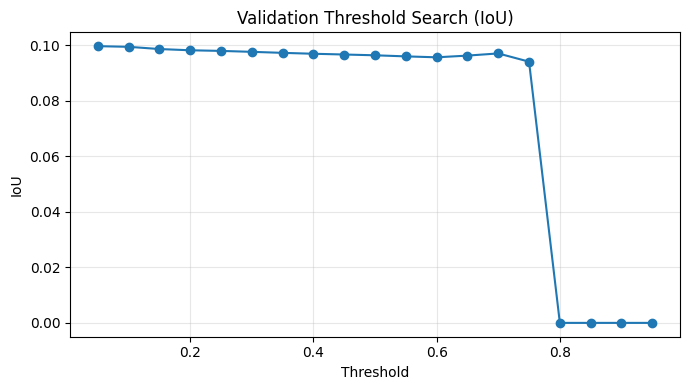

In [19]:
# Search best threshold on validation set
best_threshold, threshold_scores = search_best_threshold(
    logits=val_logits,
    targets=val_targets,
    metric_name="iou",  # can also use "iou"
    apply_sigmoid=True,  # Apply sigmoid to logits before thresholding
)

print(f"Best validation threshold (IoU): {best_threshold:.2f}")
plot_threshold_search(threshold_scores, metric_name="IoU")

### Compute metrics on the test set

Computing pixel_accuracy...
Computing precision...
Computing recall...
Computing specificity...
Computing dice_f1...
Computing iou_jaccard...
Computing mcc...
Computing auprc...

Test metrics
pixel_accuracy      : 0.1009
precision           : 0.1008
recall              : 0.9998
specificity         : 0.0001
dice_f1             : 0.1832
iou_jaccard         : 0.1008
mcc                 : -0.0050
auprc               : 0.0949
balanced_accuracy   : 0.4999


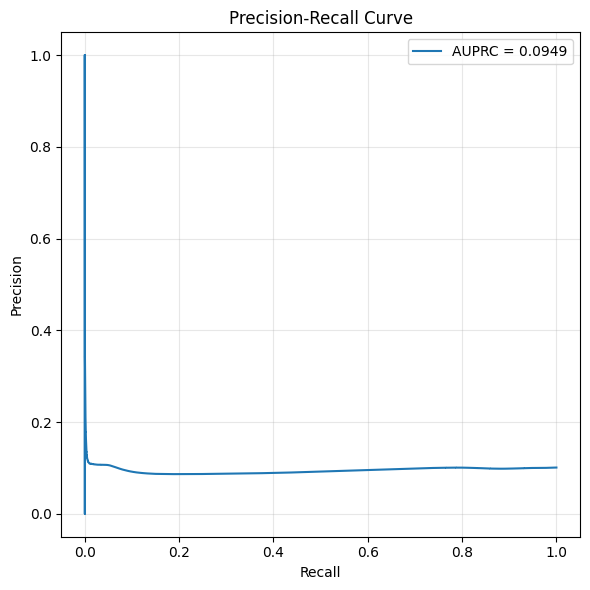

In [20]:
# Compute final test metrics using best threshold
test_metrics = compute_binary_segmentation_metrics(
    logits=test_logits,
    targets=test_targets,
    threshold=best_threshold,
    apply_sigmoid=True,  # Apply sigmoid to logits before thresholding
)

print("\nTest metrics")
for k, v in test_metrics.items():
    print(f"{k:20s}: {v:.4f}")

# Plot PR curve
plot_auprc_curve(test_logits, test_targets)

### Plot a sample prediction from the test set

In [21]:
def plot_data_label_prediction_slice(
    data,
    label,
    prob_map,
    prediction,
    size=(20, 6),
    show=True
):
    fig, axes = plt.subplots(1, 4, figsize=size)

    axes[0].imshow(data, cmap="gray")
    axes[0].set_title("Input Image")
    axes[0].axis("off")

    axes[1].imshow(label, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Ground Truth")
    axes[1].axis("off")

    im2 = axes[2].imshow(prob_map, cmap="viridis", vmin=0, vmax=1)
    axes[2].set_title("Predicted Probability")
    axes[2].axis("off")
    plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

    axes[3].imshow(prediction, cmap="gray", vmin=0, vmax=1)
    axes[3].set_title("Predicted Mask")
    axes[3].axis("off")

    plt.tight_layout()
    if show:
        plt.show()
    return fig

Data shape: (256, 256), Label shape: (256, 256), Prob map shape: (256, 256), Prediction shape: (256, 256)


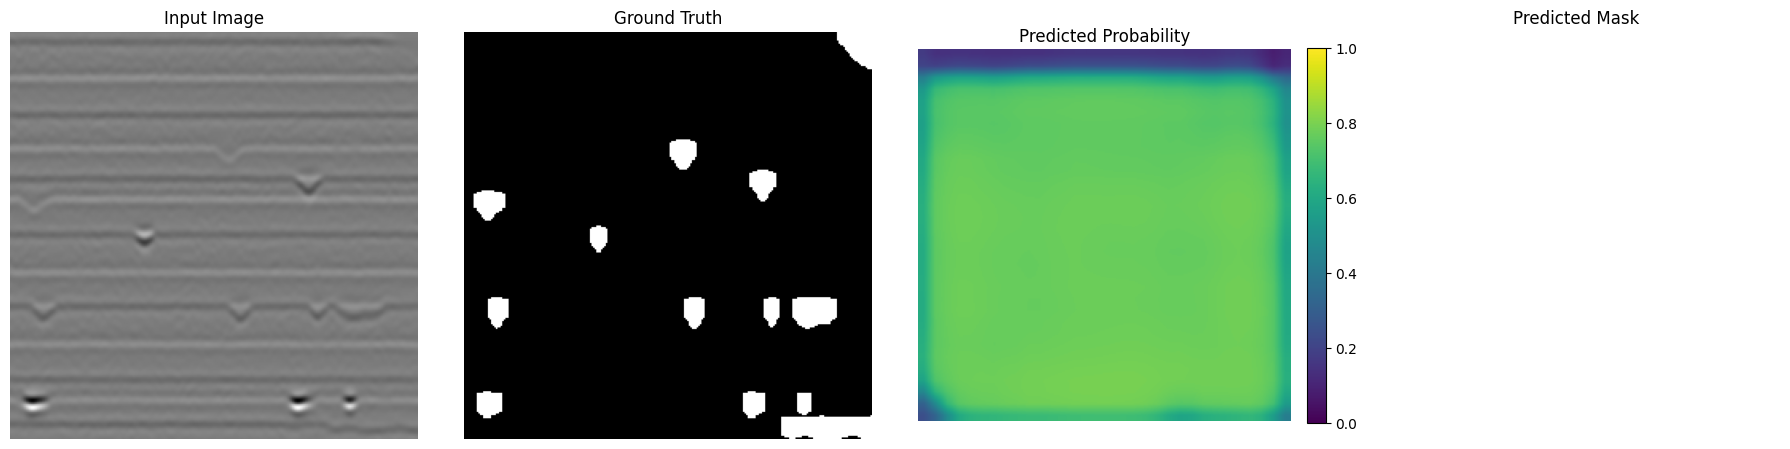

/tmp/ipykernel_1217/2941525073.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


In [22]:
index = 100

data = data_module.test_dataset[index][0][0, :, :]
label = test_targets[index].cpu().numpy()

prob_map = torch.sigmoid(test_logits[index]).cpu().numpy()
prediction = (prob_map >= best_threshold).astype(np.uint8)

print(f"Data shape: {data.shape}, Label shape: {label.shape}, Prob map shape: {prob_map.shape}, Prediction shape: {prediction.shape}")

fig = plot_data_label_prediction_slice(
    data=data,
    label=label,
    prob_map=prob_map,
    prediction=prediction,
    size=(18, 6),
)
fig.show()